# ДЗ 1. Шум, фильтры и гистограммы

Импульсный шум и шум «соль-перец», размытие, повышение резкости, медианный фильтр, гистограммы изображения (OpenCV, NumPy).

In [1]:
''' Импорт библиотек.  '''
import numpy as np
from matplotlib import pyplot as plt
import cv2 as cv
from PIL import Image, ImageDraw
import random

### Наложение импульсного шума. 

In [2]:
def apply_impulse_noise(image, noise_probability):
    '''Импульсный шум.
    Создаём объект для рисования на изображении. 
    Получаем размеры изображения. Проходимся по всем пикселям.
    Генерируем случайное для определения наложения шума.
    Накладываем шум. Возвращаем изображение.
    
    Входные данные:
    image - исходное изображение
    noise_probability - вероятность применения шума
    
    '''
    draw = ImageDraw.Draw(image)  
    width, height = image.size  
    for x in range(width): 
        for y in range(height):  
            if random.random() < noise_probability: 
                draw.point((x, y), fill = 'white')  
    return image

''' Загрузка изображения '''
input_image = Image.open('cat.JPG')

''' Применение импульсивного шума с вероятностью 0.01 '''
noisy_image = apply_impulse_noise(input_image, 0.01)

''' Сохранение результата '''
noisy_image.save('noisy_image.jpg')

### Применение блюра.

In [3]:

''' Загрузка изображения.  '''
image = cv.imread('noisy_image.jpg')

''' Применение блюра.  '''
blurred_image = cv.GaussianBlur(image, (15,15), 0) 

''' Вывод и сохранение результата ''' 
cv.imshow('Blurred Image', blurred_image)
cv.imwrite('blurred_cat.jpg', blurred_image)

''' Ожидание нажатия клавиши для закрытия окна.  '''
cv.waitKey(0)
cv.destroyAllWindows()

### Увеличение резкости. 

In [5]:
image = cv.imread('blurred_cat.jpg') 

''' Создание ядра для увеличения резкости изображения.  '''
kernel = np.array([[0, -1, 0],
                   [-1, 5, -1],
                   [0, -1, 0]])

''' Применение фильтрации с использованием ядра и filtr2D. '''
sharpened_image = cv.filter2D(image, -1, kernel)

''' Отображение увеличенной резкости изображения.  '''
cv.imshow('Sharpened Image', sharpened_image) 

''' Сохранение резкого изображения.  '''
cv.imwrite('sharpened_cat.jpg', sharpened_image) 

''' Ожидание нажатия клавиши и закрытие всех окон. '''
cv.waitKey(0)
cv.destroyAllWindows()

### Наложение шума соль-перец. 

In [9]:
def apply_sp_noise(input_image):
    """Шум соль-перец.
    Считывание изображения, загрузка информации о пикселях. 
    Проход по каждому пикселю, с вероятностью 0.1
    замены на белый или черный пиксель. 
    
    Входные данные:
    input_image - исходное изображение. 
    
    """
    pixel_map = input_image.load() 
    width, height = input_image.size 
    for i in range(width): 
        for j in range(height): 
            pix = input_image.getpixel((i, j)) 
            if random.randint(0, 21) == 1:
                pix = (255, 255, 255)
            elif random.randint(0, 21) == 0:
                pix = (0, 0, 0) 
            pixel_map[i, j] = pix
    return input_image

input_image = Image.open("sharpened_cat.jpg") 
output_image = apply_sp_noise(input_image)
output_image.save("sp_cat.jpg")

### Применение медианного фильтра. 

In [ ]:
def median_filter(input_image, filter_size):
    '''Медианный фильтр.
    Преобразуем изображение в массив NumPy. Находим 
    начальное значение для фильтра. Применяем медианный 
    фильтр к каждому каналу цвета (RGB). Находим 
    соседние пиксели и заменяем на медиану соседних.
    Создаем новое изображение из массива NumPy.
    
    Входные данные:
    input_image - исходное изображение.
    filter_size - размер фильтра.
    
    '''
    img = Image.open(input_image) 
    img_array = np.array(img) 
    img_median = np.copy(img_array) 
    start = filter_size // 2 
    
    for c in range(3):  
        for i in range(start, img_array.shape[0] - start): 
            for j in range(start, img_array.shape[1] - start):
                neighbors = img_array[i-start:i+start+1, j-start:j+start+1, c].ravel() 
                img_median[i, j, c] = np.median(neighbors) 
                
    output_image = Image.fromarray(np.uint8(img_median))
    return output_image


input_image = 'sp_cat.jpg'

''' Применяем медианный фильтр к входному изображению с размером фильтра 3x3 '''
output_image = median_filter(input_image, 3) 

''' Сохраняем полученное изображение '''
output_image.save('median_cat.jpg') 

### Работа с гистограммой изображения. 

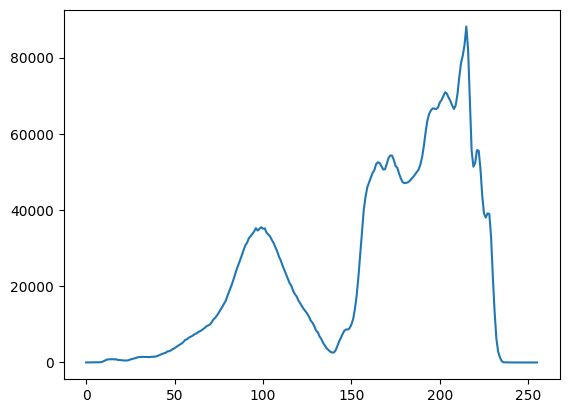

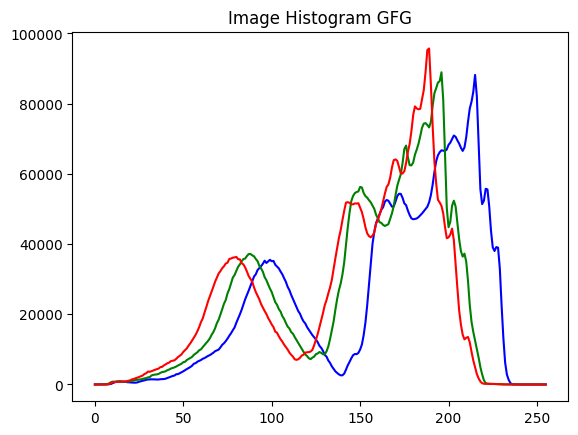

In [12]:
'''
Считывание изображения, отображение изображения
и построение гистограммы общей и для каждого
канала цвета
''' 
img = cv.imread('sea.png')

hist = cv.calcHist([img], [0], None, [256], [0, 256])
plt.plot(hist) 
plt.show()

colors = ('b','g','r') 
for i,color in enumerate(colors): 
    hist = cv.calcHist([img],[i],None,[256],[0,256]) 
    plt.plot(hist,color = color) 
plt.title('Image Histogram GFG') 
plt.show()

cv.imshow('Original image', img)
'''Считывание изображения, загрузка информации о пикселях.  '''

input_image = Image.open("sea.png") 
pixel_map = input_image.load() 
width, height = input_image.size 

"""
Проход по каждому пикселю и изменение его значения
по формуле: x = (x - x_min) * ((255 - 0) / (x_max - x_min))
"""
for i in range(width): 
    for j in range(height): 
        r, g, b = input_image.getpixel((i, j)) 
        r = (r - 10) * (255 / (200 - 10))
        g = (g - 10) * (255 / (200 - 10))
        b = (b - 10) * (255 / (200 - 10))
        pixel_map[i, j] = (int(r), int(g), int(b)) 

''' Показ и сохранение итогового изображения.  '''
cv.imshow('Edited image', img)
input_image.save("output_sea.png", format="png")